# Solutions · 16 · Bioreactors and enzyme kinetics

Worked solutions to the exercises of [notebook 16](../notebooks/16_bioreactors_and_enzyme_kinetics.ipynb). Try each exercise
yourself before reading its solution - the learning happens in the attempt. Solutions are one way to
answer each question; other correct approaches exist.

In [1]:
try:                      # on Google Colab (or anywhere engreact is missing): install it from GitHub
    import engreact
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engreact"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import integrate, optimize
from engreact import bio
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

In [2]:
mu_max, K_s, Y, S_in = 0.4, 0.2, 0.5, 20.0

## Exercise 1

Include a maintenance term m_s = 0.02 g substrate/(g cells h) and a death rate k_d = 0.01 1/h in the batch growth model, and show how they change the final biomass and the stationary phase.

final biomass: ideal 10.05 g/L; with maintenance and death 6.00 g/L (peak 9.52 at t = 13.8 h)


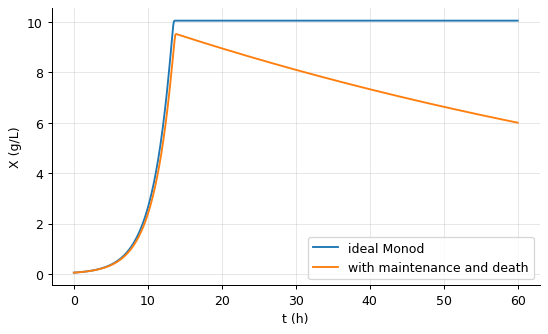

In [3]:
t = np.linspace(0, 60, 600)
plain = bio.batch_growth(0.05, 20.0, mu_max, K_s, Y, t)
real = bio.batch_growth(0.05, 20.0, mu_max, K_s, Y, t, k_d=0.01, m_s=0.02)
print(f"final biomass: ideal {plain['X'][-1]:.2f} g/L; with maintenance and death {real['X'][-1]:.2f} g/L (peak {real['X'].max():.2f} at t = {t[int(np.argmax(real['X']))]:.1f} h)")
plt.plot(t, plain["X"], label="ideal Monod"); plt.plot(t, real["X"], label="with maintenance and death"); plt.xlabel("t (h)"); plt.ylabel("X (g/L)"); plt.legend(); plt.show()

Maintenance diverts substrate from growth, lowering the peak; death makes the stationary phase a slow
decline instead of a plateau. Real growth curves show both, and fitting them with plain Monod
overestimates the yield.

## Exercise 2

Two chemostats in series (each D = 0.3 1/h relative to its own volume): compute the outlet substrate and biomass, and compare the total residence time for 99 % substrate conversion with a single chemostat.

In [4]:
D = 0.3
s1 = bio.chemostat_steady(D, S_in, mu_max, K_s, Y)
# tank 2 receives biomass, so its balances must be solved: D (X1 - X2) + mu(S2) X2 = 0, D (S1 - S2) = mu(S2) X2 / Y
def tank2(y):
    S2, X2 = y
    mu = bio.monod(S2, mu_max, K_s)
    return [D * (s1["X"] - X2) + mu * X2, D * (s1["S"] - S2) - mu * X2 / Y]
S2, X2 = optimize.fsolve(tank2, [s1["S"] / 5, s1["X"] * 1.02])
s2 = {"S": S2}
print(f"tank 1: S = {s1['S']:.3f}, X = {s1['X']:.2f}; tank 2: S = {S2:.4f}, X = {X2:.2f} g/L")
S_target = 0.01 * S_in
D1 = optimize.brentq(lambda D_: bio.chemostat_steady(D_, S_in, mu_max, K_s, Y)["S"] - S_target, 1e-4, 0.39)
print(f"99 % substrate conversion in one chemostat needs D = {D1:.3f} 1/h (residence time {1/D1:.1f} h); two tanks at D = 0.3 each (total residence {2/0.3:.1f} h) reach S = {s2['S']:.4f}, i.e. {1 - s2['S']/S_in:.2%} conversion")

tank 1: S = 0.600, X = 9.70; tank 2: S = 0.0046, X = 10.00 g/L
99 % substrate conversion in one chemostat needs D = 0.200 1/h (residence time 5.0 h); two tanks at D = 0.3 each (total residence 6.7 h) reach S = 0.0046, i.e. 99.98% conversion


The second tank receives a dense culture and runs at a substrate level far below the first, mopping up what
a single tank cannot without a long residence time - the same series advantage as for CSTRs in notebook 02.
Its balances must be solved with the incoming biomass: the library's single-tank formula (which fixes S by
mu(S) = D) assumes a sterile feed and would wrongly give the same S in both tanks.

## Exercise 3

**Implement it yourself:** integrate the batch enzyme reactor dS/dt = -V_max S/(K_m + S) with solve_ivp and compare with `bio.batch_enzyme` at 5 time points.

In [5]:
S0, V_max, K_m = 2.0, 1.0, 0.5
sol = integrate.solve_ivp(lambda t, S: [-V_max * S[0] / (K_m + S[0])], (0, 3), [S0], t_eval=[0.5, 1.0, 1.5, 2.0, 2.5], rtol=1e-10)
lib = bio.batch_enzyme(S0, V_max, K_m, sol.t)
print(pd.DataFrame({"t": sol.t, "solve_ivp": sol.y[0], "integrated MM": lib}).round(5).to_string(index=False))

  t  solve_ivp  integrated MM
0.5    1.60882        1.60882
1.0    1.23930        1.23930
1.5    0.89952        0.89952
2.0    0.60108        0.60108
2.5    0.35891        0.35891


The integrated Michaelis-Menten equation is implicit in S, so the library solves it by root finding; the
direct integration agrees to five decimals.